In [1]:
import pandas as pd

In [2]:
merged_df_original=pd.read_csv("result_NSE_differences.csv", index_col=0)
merged_df=pd.read_csv("result_NSE_differences_grt15.csv", index_col=0)

In [3]:
# Prepare data
datasets = { "Catchment":merged_df_original['Catchment'],
    "All": merged_df_original['NSE_difference'],
    ">1": merged_df['NSE_difference_gt1'],
    ">5": merged_df['NSE_difference_gt5']
}

In [4]:
datasets

{'Catchment': 0         GRDC_6140100
 1         GRDC_6140101
 2         GRDC_6140120
 3         GRDC_6140130
 4         GRDC_6140140
              ...      
 1795    camelsgb_95001
 1796    camelsgb_96001
 1797    camelsgb_96002
 1798    camelsgb_96004
 1799    camelsgb_97002
 Name: Catchment, Length: 1800, dtype: object,
 'All': 0       0.221
 1       0.247
 2       0.206
 3       0.226
 4       0.226
         ...  
 1795    0.055
 1796    0.084
 1797    0.078
 1798    0.072
 1799    0.165
 Name: NSE_difference, Length: 1800, dtype: float64,
 '>1': 0       0.296
 1       0.337
 2       0.277
 3       0.305
 4       0.304
         ...  
 1795    0.078
 1796    0.122
 1797    0.120
 1798    0.107
 1799    0.240
 Name: NSE_difference_gt1, Length: 1800, dtype: float64,
 '>5': 0       0.306
 1       0.387
 2       0.424
 3       0.297
 4       0.342
         ...  
 1795    0.170
 1796    0.223
 1797    0.293
 1798    0.253
 1799    0.379
 Name: NSE_difference_gt5, Length: 1800, dtype: floa

In [5]:
df = pd.DataFrame(datasets)
df.to_csv("NSE_differences.csv")

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def plot_hydrograph(basin, data_dir):

    # periods
    training_period = ['1980-10-01','2005-09-30']
    testing_period  = ['2006-01-01','2020-12-31']

    # read file
    subdataset_name = basin.split('_')[0].lower()
    filepath = Path(data_dir) / "timeseries" / "csv" / subdataset_name / f"{basin}.csv"

    df = pd.read_csv(filepath, parse_dates=['date'])
    df = df.set_index('date')

    # select variables
    precip = df['eobs_new']
    discharge = df['streamflow']

    # split periods
    train = df.loc[training_period[0]:training_period[1]]
    test  = df.loc[testing_period[0]:testing_period[1]]

    # create figure
    fig, ax1 = plt.subplots(figsize=(12,5))

    # discharge axis
    ax1.plot(train.index, train['streamflow'], color='blue', label='Q train')
    ax1.plot(test.index, test['streamflow'], color='red', label='Q test')
    ax1.set_ylabel("Discharge")
    ax1.set_xlabel("Date")

    # precipitation axis
    ax2 = ax1.twinx()
    ax2.bar(train.index, train['eobs_new'], width=1, alpha=0.3, label='P train')
    ax2.bar(test.index, test['eobs_new'], width=1, alpha=0.3, label='P test')
    ax2.set_ylabel("Precipitation")

    # invert precipitation axis (hydrology convention)
    ax2.invert_yaxis()

    # title
    plt.title(f"Rainfall–Runoff Hydrograph: {basin}")

    # legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.tight_layout()
    plt.show()

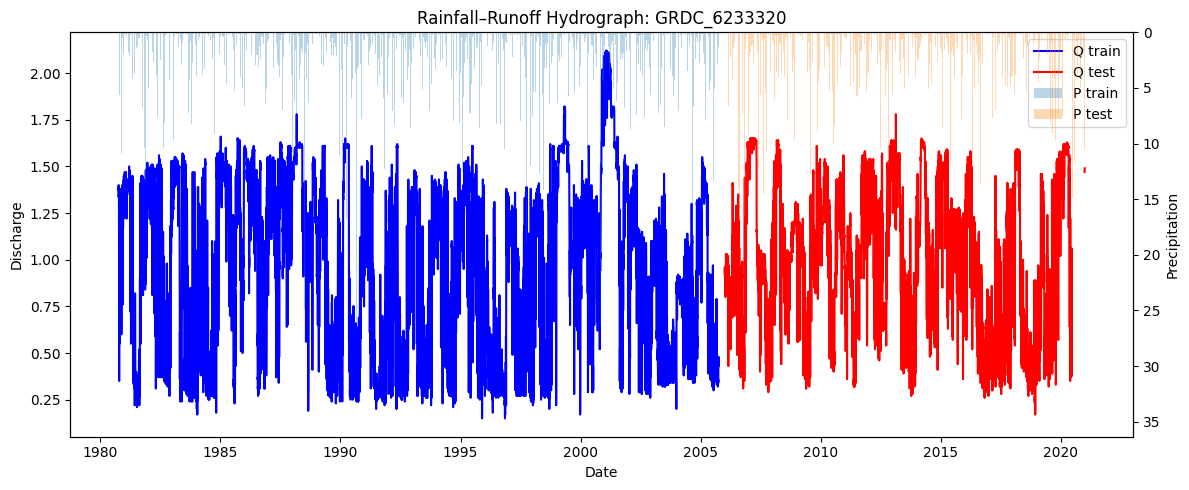

In [8]:
data_dir = Path.home() / "datasets"

plot_hydrograph("GRDC_6233320", data_dir)

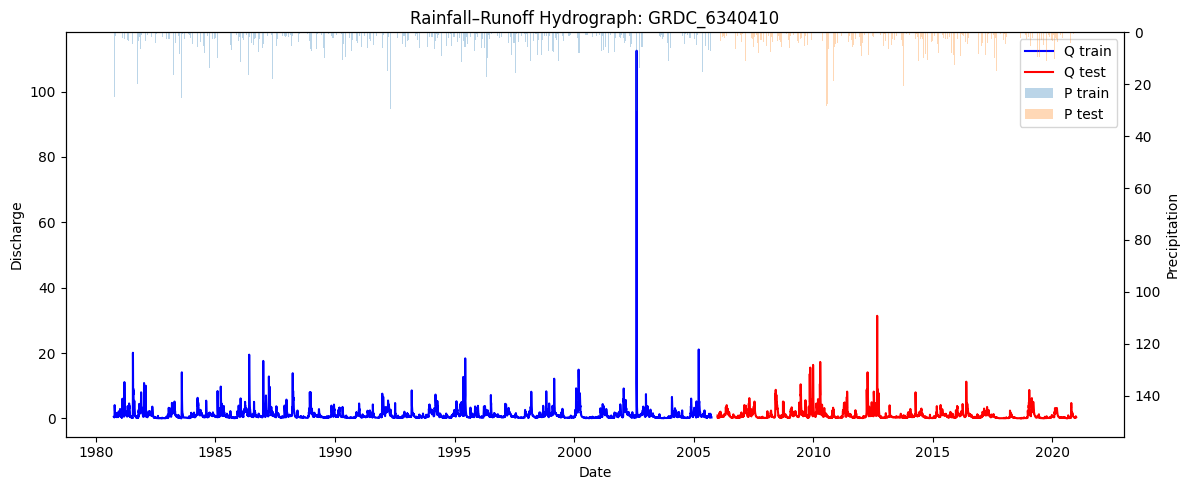

In [10]:
plot_hydrograph("GRDC_6340410", data_dir)

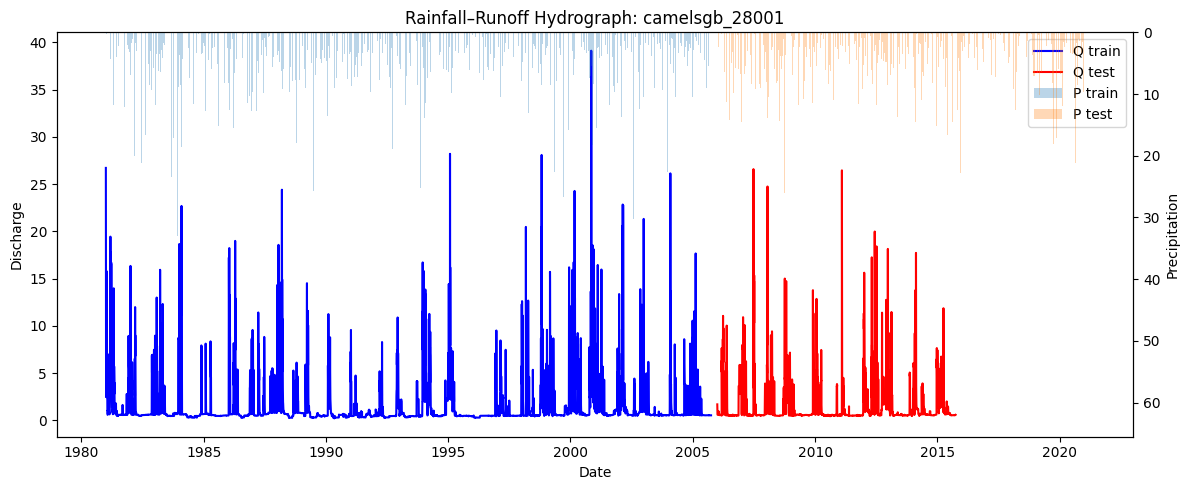

In [9]:
plot_hydrograph("camelsgb_28001", data_dir)

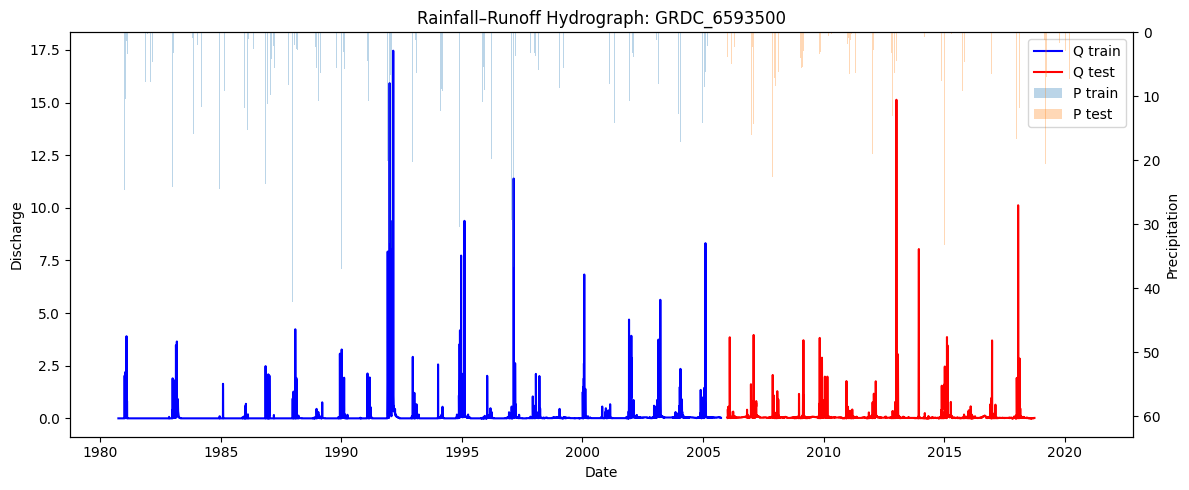

In [11]:
plot_hydrograph("GRDC_6593500", data_dir)

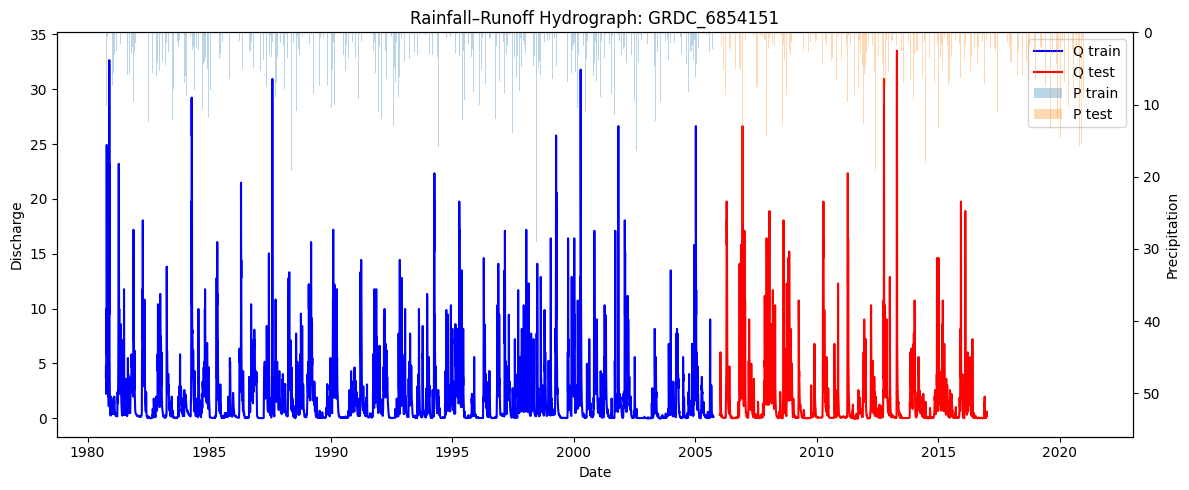

In [12]:
plot_hydrograph("GRDC_6854151", data_dir)

In [17]:
import pandas as pd
from pathlib import Path
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def plot_interactive_hydrograph(basin, data_dir):

    training_period = ['1980-10-01','2005-09-30']
    testing_period  = ['2006-01-01','2020-12-31']

    subdataset_name = basin.split('_')[0].lower()
    filepath = Path(data_dir) / "timeseries" / "csv" / subdataset_name / f"{basin}.csv"

    df = pd.read_csv(filepath, parse_dates=['date'])
    df = df.set_index('date')

    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=True,
        vertical_spacing=0.05,
        row_heights=[0.3,0.7],
        subplot_titles=("Precipitation","Discharge")
    )

    # ---- precipitation (area) ----
    fig.add_trace(
        go.Scatter(
            x=df.index,
            y=df['eobs_new'],
            fill='tozeroy',
            mode='lines',
            line=dict(width=0),
            name="Precipitation"
        ),
        row=1, col=1
    )

    # ---- discharge ----
    fig.add_trace(
        go.Scatter(
            x=df.index,
            y=df['streamflow'],
            mode="lines",
            line=dict(width=2),
            name="Discharge"
        ),
        row=2, col=1
    )

    # ---- training period shading ----
    fig.add_vrect(
        x0=training_period[0], x1=training_period[1],
        fillcolor="blue", opacity=0.08, line_width=0
    )

    # ---- testing period shading ----
    fig.add_vrect(
        x0=testing_period[0], x1=testing_period[1],
        fillcolor="red", opacity=0.08, line_width=0
    )

    fig.update_layout(
        title=f"Rainfall–Runoff Hydrograph: {basin}",
        template="plotly_white",
        height=650,
        xaxis=dict(
            rangeslider=dict(visible=True),
            type="date"
        )
    )

    fig.update_yaxes(autorange="reversed", title="Precipitation", row=1, col=1)
    fig.update_yaxes(title="Discharge", row=2, col=1)

    fig.show()

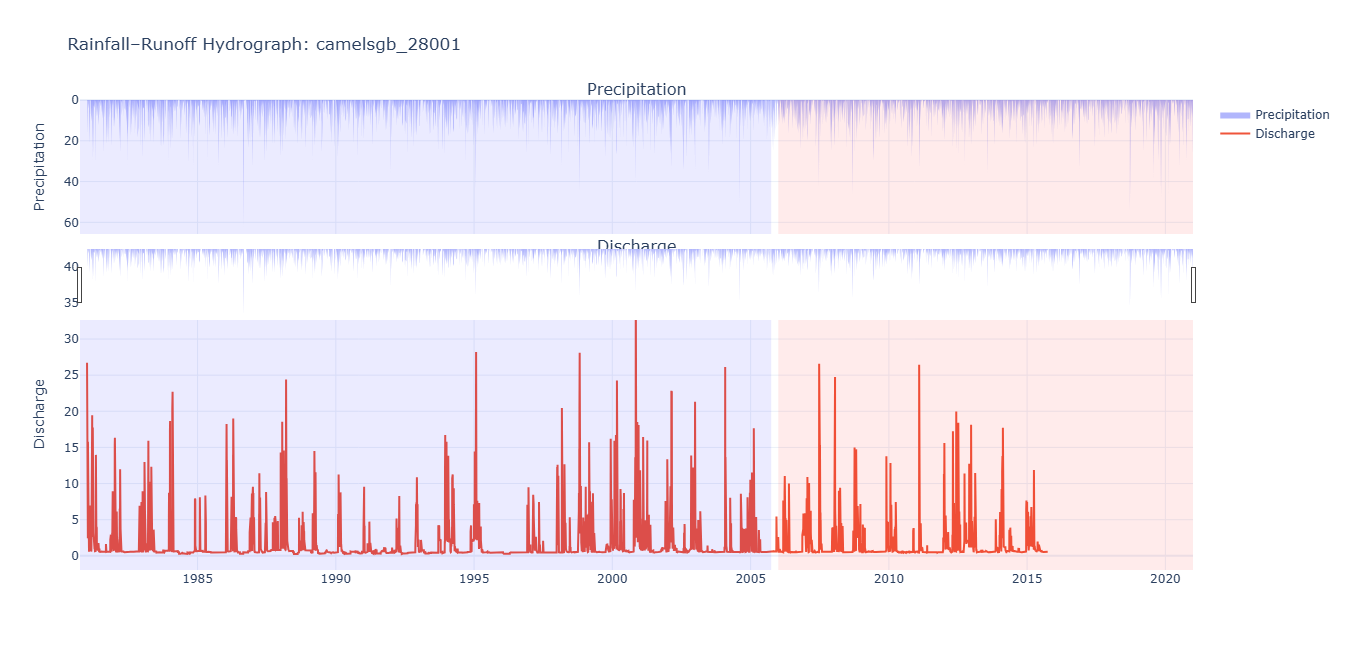

In [18]:
plot_interactive_hydrograph("camelsgb_28001", data_dir)